In [40]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [
    p for p in sys.path
    if "/opt/software-current/" not in p
]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [ ]:
import pandas as pd

df = pd.read_parquet("../clip_train.parquet")
collections_df = pd.read_csv("hi/collections.tsv000", sep="\t")

board_titles = (
    collections_df
    .groupby("photo_id")["collection_title"]
    .apply(lambda x: ", ".join(x.dropna().astype(str).unique()))
    .rename("collection_title")
)

df = df.merge(board_titles, on="photo_id", how="left")

unique_collections = (
    collections_df[
        ["collection_id", "collection_title"]
    ]
    .drop_duplicates("collection_id")
    .reset_index(drop=True)
)

In [90]:
import torch
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torch.nn.functional as F

MODEL_NAME = "google/siglip2-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"

model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

processor = AutoProcessor.from_pretrained(MODEL_NAME)

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 6326.25it/s]


In [99]:
def embed_images_batch(image_paths, batch_size: int = 1024):
    embeddings = []


    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]

        images = []
        for path in batch_paths:
            with Image.open(path) as img:
                images.append(img.convert("RGB"))

        inputs = processor(images=images, return_tensors="pt").to(device)

        with torch.inference_mode():
            output = model.get_image_features(**inputs)
            embedding = output.pooler_output
            embedding = F.normalize(embedding, p=2, dim=-1)

        embeddings.append(embedding)

    # return embedding.squeeze(0)
    return torch.cat(embeddings, dim=0)

def embed_text_batch(texts, batch_size: int = 1024):
    embeddings = []

    for start in range(0, len(texts), batch_size):

        inputs = processor(text=texts[start:start + batch_size],
            padding="max_length",            truncation=True,
 return_tensors="pt").to(device)

        with torch.inference_mode():
            output = model.get_text_features(**inputs)
            embedding = output.pooler_output
            embedding = F.normalize(embedding, p=2, dim=-1)

        embeddings.append(embedding)

    return torch.cat(embeddings, dim=0)

def embed_post_batch(
    df,
    batch_size=1024,
    image_weight=0.5,
    caption_weight=0.3,
    board_weight=0.2
):
    image_paths = df["image_path"].astype(str).tolist()
    image_embeddings = embed_images_batch(image_paths, batch_size)

    captions = df["caption"].fillna("").astype(str).tolist()
    caption_embeddings = embed_text_batch(captions, batch_size)

    boards = df["collection_title"].fillna("").astype(str).tolist()
    board_embeddings = embed_text_batch(boards, batch_size)

    embeddings = (
        image_embeddings * image_weight
        + caption_embeddings * caption_weight
        + board_embeddings * board_weight
    )

    return F.normalize(embeddings, p=2, dim=-1)

def embed_collection_batch(df, batch_size=1024):
    titles = (
        df["collection_title"]
        .fillna("")
        .astype(str)
        .tolist()
    )

    return embed_text_batch(titles, batch_size)

In [100]:
post_embeddings = embed_post_batch(df)

# collection_embeddings = embed_collection_batch(
#     unique_collections
# )

In [101]:
TESTS = ["laptop"]

for query in TESTS:
    query_embedding = embed_text_batch([query]).cpu().numpy()

    image_scores = post_embeddings.cpu().numpy() @ query_embedding.T

    df[f"score_combined_{query}"] = (
        image_scores
    )

In [102]:
# def evaluate(query, k=10):
#     ranked = df.sort_values(f"score_combined_{query}", ascending=False)
#     relevant = (ranked["class"] == query).to_numpy()

#     n_relevant = relevant.sum()
#     top_k = relevant[:k]

#     precision_k = top_k.sum() / len(top_k) if len(top_k) else 0
#     recall_k = top_k.sum() / n_relevant if n_relevant else 0

#     precisions = [
#         relevant[:i + 1].sum() / (i + 1)
#         for i in range(len(relevant))
#         if relevant[i]
#     ]

#     ap = sum(precisions) / n_relevant if n_relevant else 0

#     return precision_k, recall_k, ap

import matplotlib.pyplot as plt

# fig, axes = plt.subplots(1, len(TESTS), figsize=(5 * len(TESTS), 4))

# for ax, query in zip(axes, TESTS):
#     ax.bar(["Precision@10", "Recall@10", "AP"], evaluate(query))
#     ax.set_title(f"Combined Retrieval — {query}")
#     ax.set_ylim(0, 1)

# plt.tight_layout()
# plt.show()

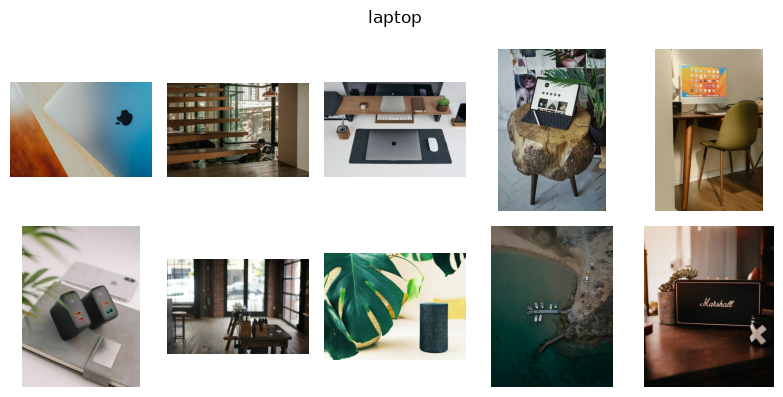

In [104]:
for query in TESTS:
    top10 = df.sort_values(
        f"score_combined_{query}",
        ascending=False
    ).head(10)

    fig, axes = plt.subplots(2, 5, figsize=(8, 4))

    for i, ax in enumerate(axes.flat):
        row = top10.iloc[i]
        ax.imshow(Image.open(row["image_path"]))
        # ax.set_title(f"Rank {i + 1}", color="green" if row["class"] == query else "red")
        ax.axis("off")

    fig.suptitle(query)
    plt.tight_layout()
    plt.show()

In [ ]:
photo_ids = df["photo_id"].tolist()

photo_to_idx = {
    photo_id: idx
    for idx, photo_id in enumerate(photo_ids)
}

collection_ids = unique_collections["collection_id"].tolist()

collection_to_idx = {
    collection_id: idx
    for idx, collection_id in enumerate(collection_ids)
}

In [ ]:
import numpy as np

edges_df = (
    collections_df[
        ["photo_id", "collection_id"]
    ]
    .drop_duplicates()
)

edges_df = edges_df[
    edges_df["photo_id"].isin(photo_to_idx)
    & edges_df["collection_id"].isin(collection_to_idx)
]

source = edges_df["photo_id"].map(photo_to_idx).to_numpy()
target = edges_df["collection_id"].map(collection_to_idx).to_numpy()

edge_index = torch.tensor(
    np.stack([source, target]),
    dtype=torch.long
)

print("Edge index:", edge_index.shape)

In [ ]:
from torch_geometric.data import HeteroData

data = HeteroData()

# Node features
data["photo"].x = post_embeddings
data["collection"].x = collection_embeddings

# Photo -> Collection
data["photo", "belongs_to", "collection"].edge_index = edge_index

# Collection -> Photo
data["collection", "contains", "photo"].edge_index = edge_index.flip(0)

print(data)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv

In [ ]:
class GraphSAGE(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=256, output_dim=128):
        super().__init__()

        self.layer1 = SAGEConv(512, 256)
        self.layer2 = SAGEConv(256, 128)

    def forward(self, x, edge_index):
        x = F.relu(self.layer1(x, edge_index))
        x = self.layer2(x, edge_index)

        return x

model = GraphSAGE().cuda()

In [ ]:
out = model(features, edge_index)